# CTR Prediction (KDD Cup 2012 search-ad clicks)

Real CTR datasets (Criteo, Avazu) are tens of GB. A manageable real alternative is OpenML's `Click_prediction_small` (dataset 1220): about 40K rows sampled from the KDD Cup 2012 Track 2 data, which is real search-ad impression logs from Tencent's search engine. Each row has the ad, advertiser, query keyword, title and description IDs, the user ID, the ad's position and the page depth, plus whether it was clicked. The click rate in this sample is about 17%, higher than raw logs because the sample was rebalanced.

All the IDs are anonymized hashes, so the work here is mostly about turning high-cardinality IDs into usable features. I use smoothed target encoding (fit on the training split only) plus count encoding.

I'm specifically interested in (a) how far logistic regression gets, (b) does a GBM add anything on top, (c) how well-calibrated are the predicted probabilities (because in ad bidding the *value* of the prediction depends on the probability being right, not just rank-correct).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.calibration import calibration_curve

DATA_DIR = Path("../../data/click_through")

In [2]:
from sklearn.datasets import fetch_openml
# OpenML 1220 = Click_prediction_small (KDD Cup 2012 Track 2 sample); cached under data/
oml = fetch_openml(data_id=1220, as_frame=True, data_home=str(DATA_DIR), parser="auto")
df = oml.frame.copy()
df["clicked"] = df.pop("click").astype(int)

print(f"shape: {df.shape}  CTR: {df['clicked'].mean():.2%}")
df.head(3)

shape: (39948, 10)  CTR: 16.84%


,impression,ad_id,advertiser_id,depth,position,keyword_id,title_id,description_id,user_id,clicked
0,1,8343295,11700,3,3,21264,27892,1559,0,0
1,1,20017077,23798,1,1,35498,4,36476,562934,1
2,1,21348354,36654,1,1,19975,36105,33292,11621116,0


In [3]:
id_cols = ["ad_id", "advertiser_id", "keyword_id", "title_id", "description_id", "user_id"]
num_cols = ["impression", "depth", "position"]

train_df, test_df = train_test_split(df, test_size=0.25, stratify=df["clicked"], random_state=21)

def encode(train_df, other_df, prior_weight=20):
    """Smoothed target mean + log count per ID column, learned from train_df only."""
    prior = train_df["clicked"].mean()
    out = other_df[num_cols].astype(float).copy()
    out["pos_over_depth"] = other_df["position"] / other_df["depth"]
    for c in id_cols:
        stats = train_df.groupby(c)["clicked"].agg(["sum", "count"])
        te = (stats["sum"] + prior * prior_weight) / (stats["count"] + prior_weight)
        out[c + "_te"] = other_df[c].map(te).fillna(prior).values
        out[c + "_logcnt"] = np.log1p(other_df[c].map(stats["count"]).fillna(0).values)
    return out

# for the training rows themselves, use 5-fold out-of-fold encoding so the
# model never sees a row's own label baked into its features
from sklearn.model_selection import KFold
X_tr_df = pd.DataFrame(index=train_df.index)
parts = []
for fit_idx, enc_idx in KFold(5, shuffle=True, random_state=21).split(train_df):
    parts.append(encode(train_df.iloc[fit_idx], train_df.iloc[enc_idx]))
X_tr_df = pd.concat(parts).loc[train_df.index]
X_te_df = encode(train_df, test_df)

X_tr, X_te = X_tr_df.values, X_te_df.values
y_tr, y_te = train_df["clicked"].values, test_df["clicked"].values

lr  = Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]).fit(X_tr, y_tr)
gbm = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=21).fit(X_tr, y_tr)

base = np.full(len(y_te), y_tr.mean())
print(f"{'base rate':9s}  AUC: 0.500   logloss: {log_loss(y_te, base):.3f}")
for name, m in [("LogReg", lr), ("GBM", gbm)]:
    p = m.predict_proba(X_te)[:, 1]
    print(f"{name:9s}  AUC: {roc_auc_score(y_te, p):.3f}   logloss: {log_loss(y_te, p):.3f}")

base rate  AUC: 0.500   logloss: 0.453
LogReg     AUC: 0.690   logloss: 0.419
GBM        AUC: 0.703   logloss: 0.412


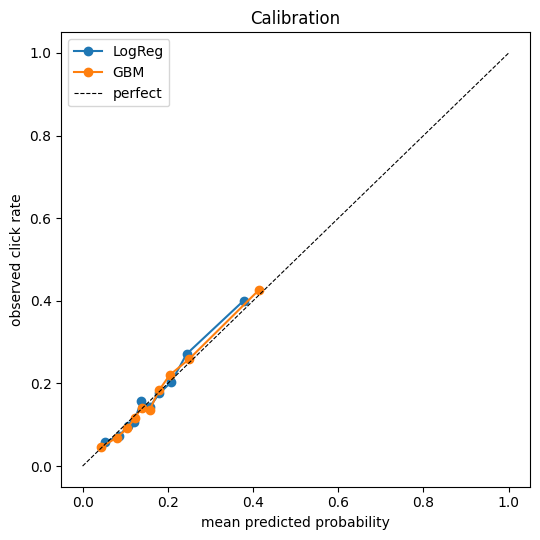

In [4]:
# calibration plot — are predicted probabilities actually believable?
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for name, m in [("LogReg", lr), ("GBM", gbm)]:
    p = m.predict_proba(X_te)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", label=name)
ax.plot([0, 1], [0, 1], "k--", linewidth=0.8, label="perfect")
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("observed click rate")
ax.set_title("Calibration"); ax.legend()
plt.tight_layout(); plt.show()

## Notes

On the 9,987 held-out impressions, logistic regression on the encoded features gets AUC 0.690 (log loss 0.419) and the GBM edges it at AUC 0.703 (log loss 0.412). Predicting the base rate for everyone gives log loss 0.453, so both models carry real but modest signal. That's normal for CTR: most of whether someone clicks isn't in the logged features.

Almost all of the signal comes from the ID encodings. Ads, advertisers and queries have very different click rates, and the smoothed target encoding is what lets a linear model use IDs with tens of thousands of values. Two details mattered for keeping the numbers honest: the encodings are learned on the training split only, and the training rows use out-of-fold encodings so a row's own click never leaks into its features.

The calibration plot is the other thing I'd look at before using these scores for bidding. In ad bidding the *value* of a prediction depends on the probability being right: if I bid on "4% click probability" and the real rate is 2%, I overpay on every impression. In production you'd fit isotonic or Platt scaling on a held-out set on top of the GBM scores, and recalibrate whenever the traffic mix shifts.